<a href="https://colab.research.google.com/github/aadhibala25/hot2026/blob/main/Aadhi_Balasubramanian_HOT_YOLO_Object_Detection_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# YOLOv8 Object Detection Training Framework

Welcome! This notebook is a framework for training an object detection model using **YOLOv8** (via the Ultralytics library).
It is designed to be highly modular and easy for the team to use.

### How it works:
Instead of writing complex custom PyTorch code, we leverage the robust `ultralytics` package. The notebook handles:
1. Taking your raw dataset (positive and negative images).
2. Automatically formatting it into a YOLO-compatible structure with a Train/Validation split.
3. Training the model.
4. Evaluating and visualizing the results.

### Important Concepts for the Team:
* **No "Background" Class:** In object detection, you do not create a class label for "background" or "negative" objects.
* **Negative Samples:** If an image does not contain any targets (poles/towers), it is a *negative image*. We simply provide an **empty `.txt` label file**. The model learns that anything not bounded by a box is the background.
* **YOLO Format:** One `.txt` file per image. Coordinates are normalized between 0 and 1 `[class_id, x_center, y_center, width, height]`.
* **Multiple Objects:** One image can contain multiple objects/classes. Each object gets its own line in the `.txt` file.

## 1. Setup & Imports

This section installs the necessary packages (including Ultralytics) and mounts Google Drive so we can access our dataset.

In [ ]:
# Install Ultralytics YOLOv8 and other required dependencies
!pip install -q ultralytics

import os
import glob
import shutil
import random
import yaml
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from sklearn.model_selection import train_test_split
from ultralytics import YOLO

# Mount Google Drive to access datasets
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=True)
    print("\n✅ Google Drive mounted successfully.")
except ImportError:
    print("\n⚠️ Not running in Google Colab or drive mounting failed.")

Mounted at /content/drive

✅ Google Drive mounted successfully.


## 2. ⚠️ EDIT THIS SECTION (Configuration)

**Teammates:** This is the main section you need to modify. Update the paths to point to your data, adjust the hyperparameters if necessary, and run the notebook.

**Do not modify the code in later sections unless you are adding custom features.**

In [ ]:
# ==========================================
# 1. PATHS (Update these to match your Drive)
# ==========================================
# Where your raw positive images and labels are currently stored
RAW_POS_IMG_DIR = "/content/drive/MyDrive/dataset_final/positive"
RAW_POS_LBL_DIR = "/content/drive/MyDrive/dataset_final/labels"

# Where your raw negative images (without labels) are stored
RAW_NEG_IMG_DIR = "/content/drive/MyDrive/dataset_final/negative"

# Where the script should build the final YOLO-formatted dataset
WORKING_DIR = "/content/drive/MyDrive/yolo_dataset"

# ==========================================
# 2. DATASET SETTINGS
# ==========================================
CLASSES = ["pole", "tower"]  # Class 0 = pole, Class 1 = tower

# Split ratios (you can adjust these, just ensure they sum to 1.0)
TRAIN_SPLIT = 0.70           # 70% for training
VAL_SPLIT = 0.20             # 20% for validation (tuning during training)
TEST_SPLIT = 0.10            # 10% for testing (unbiased final evaluation)

RANDOM_SEED = 42             # Fixed seed for reproducible splits

# ==========================================
# 3. TRAINING HYPERPARAMETERS
# ==========================================
# Model choice: yolov8n.pt (Nano - fastest), yolov8s.pt (Small), yolov8m.pt (Medium)
MODEL_CHOICE = "yolov8n.pt"
EPOCHS = 50                  # Number of training epochs
BATCH_SIZE = 16              # Number of images per batch (reduce if out of memory)
IMAGE_SIZE = 640             # YOLOv8 standard image size (it will resize automatically)

print("✅ Configuration saved!")

✅ Configuration saved!


## 3. Dataset Preparation & Train/Val/Test Split

**What this does:**
Since our current dataset is not in the final YOLO structure, this section will automatically format it for you.

**Important Notes on Data Splitting:**
* **Safe Copying:** Your original raw images and labels are NEVER modified or deleted. We copy them into a new safe working directory (`WORKING_DIR`).
* **70/20/10 Split:** By default, we split the data into 3 sets (configurable above). The model learns on the Train set, tunes itself on the Validation set during training, and finally evaluates itself on the completely unseen Test set at the end.
* **Folder Structure:** The script creates the exact folder structure YOLOv8 expects:
  * `images/train/` & `labels/train/`
  * `images/val/` & `labels/val/`
  * `images/test/` & `labels/test/`

**Steps performed here:**
1. Find all positive and negative images.
2. Split them into train/val/test sets while preserving the positive/negative ratio.
3. Copy the files into their respective folders.
4. Automatically generate empty `.txt` files for the negative images so YOLO knows they are background.

In [ ]:
import hashlib

def prep_yolo_dataset():
    # 1. Define final YOLO directories
    dirs = {
        "img_train": os.path.join(WORKING_DIR, "images/train"),
        "img_val": os.path.join(WORKING_DIR, "images/val"),
        "img_test": os.path.join(WORKING_DIR, "images/test"),
        "lbl_train": os.path.join(WORKING_DIR, "labels/train"),
        "lbl_val": os.path.join(WORKING_DIR, "labels/val"),
        "lbl_test": os.path.join(WORKING_DIR, "labels/test")
    }

    if os.path.exists(WORKING_DIR):
        shutil.rmtree(WORKING_DIR)
    for d in dirs.values():
        os.makedirs(d, exist_ok=True)

    # Helper: Robust image globbing
    def get_image_files(directory):
        valid_exts = {'.jpg', '.jpeg', '.png'}
        files = []
        if not os.path.exists(directory): return files
        for f in os.listdir(directory):
            if os.path.splitext(f)[1].lower() in valid_exts:
                files.append(os.path.join(directory, f))
        return files

    # Helper: Check for corrupted or exact duplicate images
    def filter_images(img_list, name="Dataset"):
        valid_imgs = []
        hashes = set()
        dups, corrs = 0, 0
        for img_path in img_list:
            try:
                with Image.open(img_path) as img:
                    img.verify()
                with open(img_path, 'rb') as f:
                    h = hashlib.md5(f.read()).hexdigest()
                if h in hashes:
                    dups += 1
                    continue
                hashes.add(h)
                valid_imgs.append(img_path)
            except Exception:
                corrs += 1
        print(f"[{name}] Filtered out {dups} duplicates and {corrs} corrupted images. {len(valid_imgs)} remain.")
        return valid_imgs

    # 2. Gather and filter files
    print("Scanning raw directories...")
    pos_imgs = filter_images(get_image_files(RAW_POS_IMG_DIR), "Positive Images")
    neg_imgs = filter_images(get_image_files(RAW_NEG_IMG_DIR), "Negative Images")

    # 3. Train/Val/Test Split
    def split_data(img_list):
        if not img_list:
            return [], [], []
        # First split off the training set
        train_files, temp_files = train_test_split(img_list, train_size=TRAIN_SPLIT, random_state=RANDOM_SEED)
        # Now split the remainder into validation and test sets proportionally
        val_ratio_relative = VAL_SPLIT / (VAL_SPLIT + TEST_SPLIT)
        val_files, test_files = train_test_split(temp_files, train_size=val_ratio_relative, random_state=RANDOM_SEED)
        return train_files, val_files, test_files

    pos_train, pos_val, pos_test = split_data(pos_imgs)
    neg_train, neg_val, neg_test = split_data(neg_imgs)

    # Dictionary to hold our final stats
    stats = {
        "train_pos": 0, "val_pos": 0, "test_pos": 0,
        "train_neg": 0, "val_neg": 0, "test_neg": 0,
        "classes": {c:0 for c in CLASSES}
    }

    # 4. Helper function to copy files and create labels
    def process_files(img_list, split_type, is_negative=False):
        img_dest_dir = dirs[f"img_{split_type}"]
        lbl_dest_dir = dirs[f"lbl_{split_type}"]
        success_count = 0

        for img_path in img_list:
            base_name = os.path.basename(img_path)
            name_no_ext = os.path.splitext(base_name)[0]
            dest_img_path = os.path.join(img_dest_dir, base_name)
            dest_lbl_path = os.path.join(lbl_dest_dir, f"{name_no_ext}.txt")

            if is_negative:
                shutil.copy(img_path, dest_img_path)
                open(dest_lbl_path, 'a').close()
                success_count += 1
            else:
                src_lbl_path = os.path.join(RAW_POS_LBL_DIR, f"{name_no_ext}.txt")
                if os.path.exists(src_lbl_path):
                    shutil.copy(img_path, dest_img_path)
                    shutil.copy(src_lbl_path, dest_lbl_path)
                    success_count += 1

                    # Approximate class count
                    with open(src_lbl_path, 'r') as f:
                        for line in f:
                            try:
                                cid = int(line.strip().split()[0])
                                if 0 <= cid < len(CLASSES):
                                    stats["classes"][CLASSES[cid]] += 1
                            except:
                                pass
                else:
                    print(f"⚠️ Warning: Missing label for positive image {base_name}. Skipping image.")

        # Update summary stats
        stat_key = f"{split_type}_{'neg' if is_negative else 'pos'}"
        stats[stat_key] += success_count

    # 5. Execute processing
    print("\nCopying files and processing labels... This may take a moment.")
    process_files(pos_train, "train", is_negative=False)
    process_files(pos_val, "val", is_negative=False)
    process_files(pos_test, "test", is_negative=False)
    process_files(neg_train, "train", is_negative=True)
    process_files(neg_val, "val", is_negative=True)
    process_files(neg_test, "test", is_negative=True)

    # 6. Summary Report
    print("\n===============================")
    print("✅ Dataset formatting complete!")
    print("===============================")
    print(f"Total Train Images: {stats['train_pos'] + stats['train_neg']} (Pos: {stats['train_pos']}, Neg: {stats['train_neg']})")
    print(f"Total Val Images:   {stats['val_pos'] + stats['val_neg']} (Pos: {stats['val_pos']}, Neg: {stats['val_neg']})")
    print(f"Total Test Images:  {stats['test_pos'] + stats['test_neg']} (Pos: {stats['test_pos']}, Neg: {stats['test_neg']})")
    print("Approximate Class Occurrences (across all splits):")
    for c_name, count in stats["classes"].items():
        print(f"  -> {c_name}: {count}")

# Run the preparation
prep_yolo_dataset()

Scanning raw directories...
[Positive Images] Filtered out 0 duplicates and 0 corrupted images. 2621 remain.
[Negative Images] Filtered out 0 duplicates and 0 corrupted images. 2510 remain.

Copying files and processing labels... This may take a moment.
⚠️ Warning: Missing label for positive image 6945761388776591_jpg.rf.NYI10TNsH2qNBzWCEK1L.jpg. Skipping image.
⚠️ Warning: Missing label for positive image 1659129434630830_jpg.rf.l4C1vcnRUgapGgp9RdSu.jpg. Skipping image.
⚠️ Warning: Missing label for positive image 1147024499103924_jpg.rf.VzUSVLOWnZWqQwfbesJ9.jpg. Skipping image.
⚠️ Warning: Missing label for positive image 961854639046250_jpg.rf.i9b6f3U8fWnhZUwVUnG0.jpg. Skipping image.
⚠️ Warning: Missing label for positive image 1113926135774048_jpg.rf.4cpUimHHs1ErGlnKufdP.jpg. Skipping image.
⚠️ Warning: Missing label for positive image 6697353456970149_jpg.rf.f01tucHELpwGdW7PJjR6.jpg. Skipping image.
⚠️ Warning: Missing label for positive image 1017361699585853_jpg.rf.dFDrJk4MEpWE

## 4. Generate data.yaml & Dataset Sanity Checks

**What this does:**
* Generates the `data.yaml` file required by YOLOv8, which tells the model where the data is and what the classes are.
* Runs a sanity check to ensure every image has a corresponding label file, and that the annotations format is valid (no corrupted class IDs).

In [ ]:
# 1. Generate data.yaml
yaml_path = os.path.join(WORKING_DIR, "data.yaml")
yaml_data = {
    'train': os.path.join(WORKING_DIR, "images/train"),
    'val': os.path.join(WORKING_DIR, "images/val"),
    'test': os.path.join(WORKING_DIR, "images/test"),
    'nc': len(CLASSES),
    'names': CLASSES
}

with open(yaml_path, 'w') as f:
    yaml.dump(yaml_data, f, default_flow_style=False)
print(f"✅ data.yaml created at: {yaml_path}")

# # 2. Advanced Sanity Checks
# def sanity_check():
#     print("\nRunning Sanity Checks...")
#     issues_found = 0

#     for split in ["train", "val", "test"]:
#         img_dir = os.path.join(WORKING_DIR, f"images/{split}")
#         lbl_dir = os.path.join(WORKING_DIR, f"labels/{split}")

#         images = glob.glob(os.path.join(img_dir, "*.*[gG]"))

#         for img_path in images:
#             name_no_ext = os.path.splitext(os.path.basename(img_path))[0]
#             lbl_path = os.path.join(lbl_dir, f"{name_no_ext}.txt")

#             # Check 1: Does label exist?
#             if not os.path.exists(lbl_path):
#                 print(f"❌ ERROR: Missing label file for {img_path}")
#                 issues_found += 1
#                 continue

#             # Try getting actual image dims for pixel validation
#             try:
#                 with Image.open(img_path) as img:
#                     img_w, img_h = img.size
#             except:
#                 print(f"❌ ERROR: Cannot read dimensions for {img_path}")
#                 issues_found += 1
#                 continue

#             # Check 2: Strong Format Verification
#             with open(lbl_path, 'r') as f:
#                 lines = f.readlines()
#                 for i, line in enumerate(lines):
#                     parts = line.strip().split()
#                     if not parts: continue # Skip empty lines (valid for negatives)

#                     if len(parts) != 5:
#                         print(f"❌ ERROR: Line {i+1} in {lbl_path} has {len(parts)} values. Expected exactly 5.")
#                         issues_found += 1
#                         continue

#                     try:
#                         class_id = int(parts[0])
#                         x_c, y_c, w, h = map(float, parts[1:])

#                         # Verify Class ID
#                         if class_id not in [0, 1]:
#                             print(f"❌ ERROR: Invalid class ID {class_id} in {lbl_path}")
#                             issues_found += 1

#                         # Verify Normalized Bounds
#                         if not (0 <= x_c <= 1 and 0 <= y_c <= 1):
#                             print(f"❌ ERROR: Center coords out of bounds [0,1] in {lbl_path}")
#                             issues_found += 1
#                         if not (0 < w <= 1 and 0 < h <= 1):
#                             print(f"❌ ERROR: Width/Height out of bounds (0,1] in {lbl_path}")
#                             issues_found += 1

#                         # Check 3: Pixel Bounds Validation
#                         px_w, px_h = w * img_w, h * img_h
#                         if px_w < 1 or px_h < 1:
#                             print(f"⚠️ WARNING: Suspiciously small box (zero-area) in {lbl_path}")

#                         x_min = (x_c - w/2) * img_w
#                         x_max = (x_c + w/2) * img_w
#                         y_min = (y_c - h/2) * img_h
#                         y_max = (y_c + h/2) * img_h

#                         if x_min < -2 or y_min < -2 or x_max > img_w + 2 or y_max > img_h + 2:
#                             print(f"⚠️ WARNING: Box out of image bounds in {lbl_path}. BBox: [xmin={x_min:.1f}, ymin={y_min:.1f}, xmax={x_max:.1f}, ymax={y_max:.1f}], Image: {img_w}x{img_h}")

#                     except ValueError:
#                         print(f"❌ ERROR: Non-numeric values in {lbl_path}: {line.strip()}")
#                         issues_found += 1

#     if issues_found == 0:
#         print("✅ All sanity checks passed! Dataset is healthy.")
#     else:
#         print(f"⚠️ Found {issues_found} hard errors. Please review your dataset logs.")

# sanity_check()

✅ data.yaml created at: /content/drive/MyDrive/yolo_dataset/data.yaml


## 5. Annotation Visualization

**What this does:**
Randomly samples a few images from the newly created training set and draws the bounding boxes.
**Teammates:** Check this to visually verify that the coordinates and classes are aligned correctly before starting a long training run. *Note: If a negative image is selected, it will display no boxes, which is correct!*

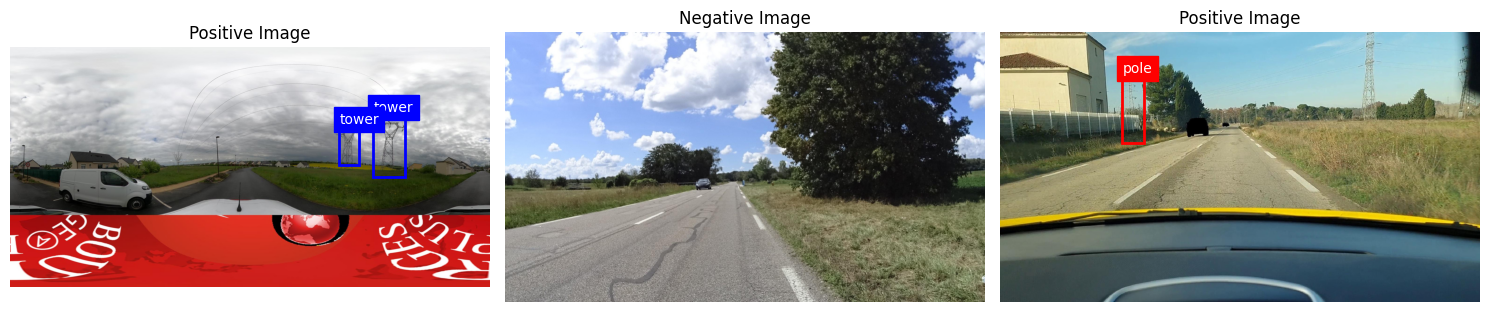

In [ ]:
def visualize_dataset_samples(num_samples=3):
    train_imgs = glob.glob(os.path.join(WORKING_DIR, "images/train", "*.*[gG]"))
    if not train_imgs:
        print("No training images found to visualize.")
        return

    # Randomly pick images
    samples = random.sample(train_imgs, min(num_samples, len(train_imgs)))

    fig, axes = plt.subplots(1, len(samples), figsize=(15, 5))
    if len(samples) == 1: axes = [axes]

    for ax, img_path in zip(axes, samples):
        img = Image.open(img_path)
        ax.imshow(img)
        ax.axis('off')

        # Find matching label
        name_no_ext = os.path.splitext(os.path.basename(img_path))[0]
        lbl_path = os.path.join(WORKING_DIR, "labels/train", f"{name_no_ext}.txt")

        width, height = img.size
        has_boxes = False

        if os.path.exists(lbl_path):
            with open(lbl_path, 'r') as f:
                for line in f.readlines():
                    has_boxes = True
                    class_id, x_center, y_center, w, h = map(float, line.strip().split())

                    # Convert YOLO normalized coordinates to absolute pixels
                    x_min = (x_center - w/2) * width
                    y_min = (y_center - h/2) * height
                    box_w = w * width
                    box_h = h * height

                    class_name = CLASSES[int(class_id)]
                    color = 'red' if class_id == 0 else 'blue'

                    rect = patches.Rectangle((x_min, y_min), box_w, box_h, linewidth=2, edgecolor=color, facecolor='none')
                    ax.add_patch(rect)
                    ax.text(x_min, y_min - 5, class_name, color='white', fontsize=10, backgroundcolor=color)

        title = "Negative Image" if not has_boxes else "Positive Image"
        ax.set_title(title)

    plt.tight_layout()
    plt.show()

visualize_dataset_samples()

## 6. Model Loading

**What this does:**
Initializes the YOLOv8 model using the pre-trained weights specified in the Configuration section (e.g., `yolov8n.pt`). YOLOv8 handles the underlying PyTorch architecture automatically.

In [ ]:
# Load the YOLOv8 model
print(f"Loading model architecture: {MODEL_CHOICE}...")
model = YOLO(MODEL_CHOICE)
print("✅ Model loaded successfully.")

Loading model architecture: yolov8n.pt...
✅ Model loaded successfully.


## 7. Training

**What this does:**
Kicks off the training loop.

**Note on Preprocessing and Augmentations:**
You do **not** need to manually preprocess your images (like blurring, resizing, rotating, or flipping)! One of the biggest advantages of Ultralytics YOLOv8 is that it handles standard preprocessing and data augmentations on the fly during training:
* **Resizing:** It automatically resizes all images to `IMAGE_SIZE` (default 640) while correctly scaling the bounding boxes to match.
* **Augmentations:** Under the hood, it applies random scaling, translations, flips, and Mosaic (combining 4 images into one) to make your model more robust.

If you want to manually tweak specific augmentations, you can pass them directly to the `model.train()` function below. Here is an example of arguments you could add:
```python
# Example of custom augmentations (add these inside model.train() if needed):
# degrees=10.0,  # Random rotations between -10 and 10 degrees
# fliplr=0.5,    # Flip left-right with 50% probability
# hsv_h=0.015,   # Adjust hue (simulates different lighting)
```

In [ ]:
# Start training
# All arguments (epochs, batch, imgsz) come from the Configuration section above.
# Results will automatically be saved by Ultralytics in the 'runs/detect/train' folder.

print("Starting training process...")
results = model.train(
    data=yaml_path,       # Path to our generated data.yaml
    epochs=2,        # Number of training loops
    batch=BATCH_SIZE,     # Batch size
    imgsz=IMAGE_SIZE,     # Image size for auto-resizing
    project=WORKING_DIR,  # Where to save training runs
    name="train_run",     # Name of the output folder
    exist_ok=True,        # Overwrite previous run with the same name if needed
    seed=RANDOM_SEED      # Reproducibility
)

Starting training process...
Ultralytics 8.4.43 🚀 Python-3.12.13 torch-2.10.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=2, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train_run, nbs=64, nms=False, opset=None, optimize=False, o

## 8. Validation & Testing

**What this does:**
Evaluates the trained model to calculate metrics like Precision, Recall, and mAP (Mean Average Precision).

1.  First, it evaluates on the **Validation set**. (This set was slightly exposed to the model during training tuning).
2.  Second, it evaluates on the **Test set**. (This is a completely hidden holdout set, giving you an unbiased final grade for how the model will perform in the real world).

In [ ]:
# Validate the model
print("\n--- Preparing Evaluation ---")

# Best practice: reload the best saved weights before evaluation
best_model_path = os.path.join(WORKING_DIR, "train_run", "weights", "best.pt")
if os.path.exists(best_model_path):
    print(f"Loading best model weights from: {best_model_path}")
    val_model = YOLO(best_model_path)
else:
    print("⚠️ 'best.pt' not found. Falling back to the current in-memory model.")
    val_model = model

# 1. Run the validation metrics on the Validation Set
print("\n--- Evaluating on Validation Set ---")
metrics_val = val_model.val(
    data=yaml_path,
    split="val",
    project=WORKING_DIR,
    name="val_run",
    exist_ok=True
)

# 2. Run the validation metrics on the Test Set
print("\n--- Evaluating on Test Set ---")
metrics_test = val_model.val(
    data=yaml_path,
    split="test",
    project=WORKING_DIR,
    name="test_run",
    exist_ok=True
)

print("\n✅ Evaluation Complete. Check the 'val_run' and 'test_run' folders in your WORKING_DIR for detailed graphs.")


--- Preparing Evaluation ---
Loading best model weights from: /content/drive/MyDrive/yolo_dataset/train_run/weights/best.pt

--- Evaluating on Validation Set ---
Ultralytics 8.4.43 🚀 Python-3.12.13 torch-2.10.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 73 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.7±0.4 ms, read: 53.9±14.0 MB/s, size: 308.9 KB)
val: Scanning /content/drive/MyDrive/yolo_dataset/labels/val.cache... 1026 images, 504 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1026/1026 226.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 65/65 2.9s/it 3:06
                   all       1026        813      0.533      0.532      0.527      0.205
                  pole        314        510      0.493      0.338      0.364      0.117
                 tower        211        303      0.573      0.726       0.69      0.292
Speed: 1.2ms preprocess, 145.1ms inference

## 9. Inference / Prediction Visualization

**What this does:**
Tests the trained model on a few validation images to see how well it predicts "in the wild".


0: 640x640 (no detections), 206.7ms
1: 640x640 (no detections), 206.7ms
2: 640x640 2 towers, 206.7ms
Speed: 5.3ms preprocess, 206.7ms inference, 12.8ms postprocess per image at shape (1, 3, 640, 640)


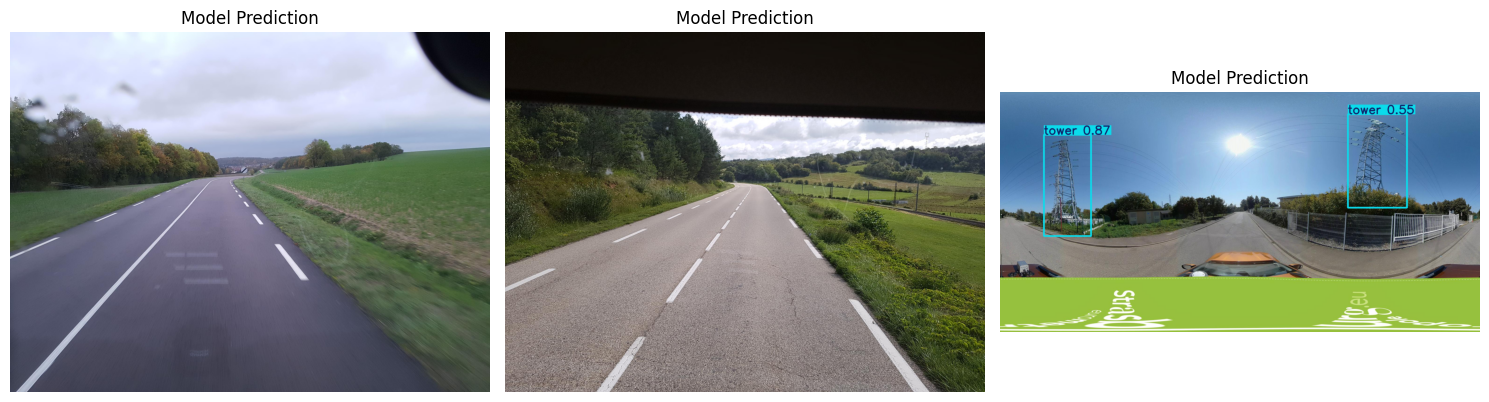

In [ ]:
def run_inference_sample(num_samples=3):
    val_imgs = glob.glob(os.path.join(WORKING_DIR, "images/val", "*.*[gG]"))
    if not val_imgs:
        print("No validation images found.")
        return

    samples = random.sample(val_imgs, min(num_samples, len(val_imgs)))

    # Best practice: run inference using the best saved weights
    best_model_path = os.path.join(WORKING_DIR, "train_run", "weights", "best.pt")
    inf_model = YOLO(best_model_path) if os.path.exists(best_model_path) else model

    # Run inference
    # The model will return a list of Results objects
    predictions = inf_model.predict(samples, conf=0.25) # conf=0.25 hides very low confidence boxes

    # Plot results
    fig, axes = plt.subplots(1, len(samples), figsize=(15, 5))
    if len(samples) == 1: axes = [axes]

    for ax, result in zip(axes, predictions):
        # Ultralytics provides a handy plot() method that returns a numpy array image with boxes drawn
        res_plotted = result.plot()
        # Convert BGR (OpenCV format) to RGB for matplotlib
        res_plotted_rgb = res_plotted[..., ::-1]

        ax.imshow(res_plotted_rgb)
        ax.axis('off')
        ax.set_title("Model Prediction")

    plt.tight_layout()
    plt.show()

run_inference_sample()

## 10. Saving Results / Next Steps

**What this does:**
The best performing model weights are automatically saved by YOLOv8 at `<WORKING_DIR>/train_run/weights/best.pt`.

This final cell simply confirms the location of your weights so your team can download them for deployment or inference on edge devices.

In [ ]:
best_model_path = os.path.join(WORKING_DIR, "train_run", "weights", "best.pt")

if os.path.exists(best_model_path):
    print("🎉 Training successful!")
    print(f"Your best model weights are saved at: {best_model_path}")
    print("\nNext Steps:")
    print("- Download 'best.pt' to use in your deployment code.")
    print("- Check the graphs in the 'train_run' and 'val_run' folders to analyze performance.")
else:
    print("⚠️ Could not locate best.pt. Check the training logs above for errors.")

🎉 Training successful!
Your best model weights are saved at: /content/drive/MyDrive/yolo_dataset/train_run/weights/best.pt

Next Steps:
- Download 'best.pt' to use in your deployment code.
- Check the graphs in the 'train_run' and 'val_run' folders to analyze performance.
